In [1]:
import xarray as xr
import torch
import numpy as np
import datetime
import cftime
import matplotlib.pyplot as plt
import sys
import re
import matplotlib.colors as colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean 
import fsspec
import xesmf as xe
from scipy.stats import pearsonr
import os
import cmocean
from functions import *

%load_ext autoreload
%autoreload 2

In [2]:

# 5. Variable Mappings
OCEAN_FIELD_NAME_PREFIXES = {
    'thetao': ['thetao_'], 'so': ['so_'], 'uo': ['uo_'], 'vo': ['vo_'],
    'zos': ['zos'], 'sea_surface_temperature': ['sst'], 'lev': ['idepth_']
}

# 6. Plotting Constants
BASINS_TO_PLOT = ['Atlantic', 'Pacific', 'Indian', 'Southern']

DEPTH_SLICES = [
    {'min': 0, 'max': 700, 'title': 'Surface (0-700m)'},
    {'min': 700, 'max': 2000, 'title': 'Intermediate (700-2000m)'},
    {'min': 2000, 'max': 7000, 'title': 'Deep (2000-7000m)'}
]
VAR_CONFIG = {
    'thetao': {'cmap': cmocean.cm.thermal, 'units': '$^\\circ$C', 'label': 'Temperature', 'centered': False},
    'so': {'cmap': cmocean.cm.haline, 'units': 'psu', 'label': 'Salinity', 'centered': False},
    'ohc': {'cmap': cmocean.cm.thermal, 'units': 'J', 'label': 'Total Heat Content', 'centered': False},
    'zos':    {'cmap': cmocean.cm.balance, 'units': 'm',         'label': 'SSH',         'centered': True},
    'uo':     {'cmap': cmocean.cm.balance, 'units': 'm/s',       'label': 'U-Velocity',  'centered': True},
    'vo':     {'cmap': cmocean.cm.balance, 'units': 'm/s',       'label': 'V-Velocity',  'centered': True},
}

# Constants
RHO = 1035          # Reference density (kg/m^3)
CP = 3850           # Specific heat capacity (J/kg/K)
SCALE_FACTOR = 1e21 # Scale to ZJ (10^21 J)


DEPTH_LAYERS = [
    {'title':'2.5m','index':0},
    {'title':'700m','index':10},
    {'title':'2000m','index':14},
    {'title':'3000m','index':15}
]
# Configuration
BASINS_TO_PLOT = ['Atlantic', 'Pacific', 'Indian', 'Southern']

In [3]:

# 1. Output Directory (Configurable Name)
OUTPUT_DIR = "Emulator_Evaluation_Figures_1deg_All_New"

my_key = "XL8EJRUDQ7QPDJSUUC8Q"
my_secret = "2HaAeDBeiyGBxeeS60t6iOrrwgW6iebpiqoYkAHM"
fs = fsspec.filesystem("s3", key = my_key, secret = my_secret, client_kwargs={"endpoint_url": "https://nyu1.osn.mghpcc.org"})
storage_options = {"key": my_key, "secret": my_secret, "client_kwargs": {"endpoint_url": "https://nyu1.osn.mghpcc.org"}}


# 2. Emulator Configuration 
# Format: (Path, Label, Color)
# You can add or remove entries here to compare any number of emulators.
EMULATOR_CONFIGS = [
    (
        '/global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/checkpoints/2025-12-19-samudra_om4_quarterdeg_eval5/predictions.zarr',
        "WDMSE-1/4deg", 
        "tab:orange"
    ),
]

# 3. Truth & Aux Paths
TRUTH_PATH = "/pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/quarterdeg/OM4.zarr"
TRUTH_LABEL = "(OM4-1/4deg)"

LEVS_PATH = '/pscratch/sd/a/asubel/Data/Chapter_2/CM4_CMIP_New.zarr/'
OCEAN_SAMPLE_PATH = '/pscratch/sd/a/asubel/full-model/scratch/ocean_sample.nc'
STATIC_GRID_PATH = 's3://emulators/am16581/ocean_static_no_mask_table.zarr'

print(f"Output Directory: {OUTPUT_DIR}")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Load Data
print("Loading Truth Data...")
if "s3" in TRUTH_PATH:
    data_truth_ocean = xr.open_zarr(TRUTH_PATH, storage_options=storage_options)
else:
    data_truth_ocean = xr.open_zarr(TRUTH_PATH)

print("Loading Emulators...")
emulators_raw = []
emulator_labels = []
emulator_colors = []

for path, label, color in EMULATOR_CONFIGS:
    try:
        print(f" - Loading {label} from {path}...")
        ds = xr.open_zarr(path).rename({'lat':'y','lon':'x'})
        emulators_raw.append(ds)
        emulator_labels.append(label)
        emulator_colors.append(color)
    except Exception as e:
        print(f"   Error loading {label}: {e}")

if not emulators_raw:
    print("No emulators loaded. Exiting.")

# Sync Time (Assume all emulators align with first emulator, truth aligns with them)
time_slice = slice(emulators_raw[0].time.values[0], emulators_raw[0].time.values[-1])
data_truth_ocean = data_truth_ocean.sel(time=time_slice)

# Load Aux Data
print("Loading Auxiliary Data...")
levs = xr.open_zarr(LEVS_PATH)['lev'].values
ocean_test = xr.open_dataset(OCEAN_SAMPLE_PATH)
depth_levels = concat_levels(ocean_test, 'idepth', 'levels')
dz_from_data = (depth_levels[1:] - depth_levels[:-1]).data

# Load Grid & Generate Masks
shape_processed = (emulators_raw[0].y.size, emulators_raw[0].x.size)
print(f"Loading target grid for shape {shape_processed}...")
target_grid_path = f"s3://emulators/am16581/grids/gaussian_grid_{shape_processed[0]}_by_{shape_processed[1]}.zarr"
target_grid = xr.open_zarr(target_grid_path, storage_options=storage_options)
target_grid_path = f"s3://emulators/am16581/grids/gaussian_grid_{shape_processed[0]}_by_{shape_processed[1]}.zarr"
target_grid = xr.open_zarr(target_grid_path, storage_options=storage_options)
    
target_grid = target_grid.rename({
    "grid_x": "x_b", "grid_y": "y_b", "grid_xt": "x", "grid_yt": "y",
    "grid_lon": "lon_b", "grid_lat": "lat_b", "grid_lont": "lon", "grid_latt": "lat",
}).compute()

print("Regridding basin mask...")
ds_static = xr.open_zarr(STATIC_GRID_PATH, storage_options=storage_options)
ds_source = ds_static[['basin', 'geolat', 'geolon']].rename({'geolat': 'lat', 'geolon': 'lon'})
ds_target = target_grid[['lat', 'lon']]
regridder = xe.Regridder(ds_source, ds_target, method='nearest_s2d', periodic=True, reuse_weights=False)
basin_regridded = regridder(ds_source['basin'])

# Grid Metrics
R = 6.371e6
dx_deg = target_grid['lon_b'].diff('x_b')[:-1].values
dy_deg = target_grid['lat_b'].diff('y_b')[:,:-1].values
dx_cal = np.deg2rad(dx_deg)*np.cos(np.deg2rad(target_grid['lat'].values))*R
dy_cal = np.deg2rad(dy_deg)*R

grid_metrics = {
    'dx': (['y','x'], dx_cal),
    'dy': (['y','x'], dy_cal),
    'areacello': (['y','x'], xe.util.cell_area(target_grid, R).values),
    'basin': (['y','x'], basin_regridded.values) 
}

# Process Data
print("Processing Datasets...")
dataset_truth = data_truth_ocean
# for metric, data in grid_metrics.items():
#     dataset_truth[metric] = data
#     dataset_truth = dataset_truth.set_coords(metric)

dataset_truth = process_dataset(dataset_truth, levs, dz_from_data, grid_metrics)

processed_emulators = []
for emu_ds in emulators_raw:
    processed_emulators.append(process_dataset(emu_ds, levs, dz_from_data, grid_metrics))

# Construct Emulator Dictionary
emulators_to_analyze = {}
for i, ds in enumerate(processed_emulators):
    emulators_to_analyze[emulator_labels[i]] = {'ds': ds, 'color': emulator_colors[i]}


Output Directory: Emulator_Evaluation_Figures_1deg_All_New
Loading Truth Data...
Loading Emulators...
 - Loading WDMSE-1/4deg from /global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/checkpoints/2025-12-19-samudra_om4_quarterdeg_eval5/predictions.zarr...
Loading Auxiliary Data...
Loading target grid for shape (720, 1440)...
Regridding basin mask...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/xarray/computation/apply_ufunc.py:305: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 12.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (270, 360).
  result_var = func(*data_vars)


Processing Datasets...


In [ ]:
# Basin Masks
basin_masks = extract_basin_masks(dataset_truth)

# --- Run Plots ---
print("\nStarting Plotting Sequence...")

from functions import *

# 6. Time Series (Thetao)
plot_mean_timeseries_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='thetao', 
    var_units='$^\\circ$C', 
    var_label='Temperature',
    output_dir=OUTPUT_DIR,
    TRUTH_LABEL = TRUTH_LABEL
)

# 7. Time Series (Salinity)
plot_mean_timeseries_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='so', 
    var_units='psu', 
    var_label='Salinity',
    output_dir=OUTPUT_DIR,
    TRUTH_LABEL = TRUTH_LABEL
)

plot_variance_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\\circ$C',
    output_dir=OUTPUT_DIR ,
    colorbar_fix=True
)

plot_variance_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='so', 
    units='psu',
    output_dir=OUTPUT_DIR,
    colorbar_fix=True
)    
print(f"\nAll plots generated successfully in: {os.path.abspath(OUTPUT_DIR)}")


Starting Plotting Sequence...
Generating Time Series for Temperature...


Here we look at how the ocean takes up heat over the inference rollout. To remove the shorter signal corresponding to seasonality, we remove climatology before computing this values. We look at this over the upper ocean, mid depth, and deep ocean as we expect signals of decreasing strength as we go to the deep ocean. We first compute OHC as  $$OHC(t) = \sum_{k \in Z} \sum_{j} \sum_{i} \rho_0 c_p \theta_{i,j,k,t} \Delta z_{k} A_{i,j}$$

We then compute the anomaly as $$\Delta OHC(t) = OHC(t)-OHC(0)$$

Here we look at the mean bias in each major ocean basin. This bias is computed as the difference between the mean state of the emulator and the mean state of OM4, as such this can average out a lot of errors.

Calculating Truth OHC Zonal Profiles...

Generating OHC Zonal Bias Plot for WDMSE-1deg...
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')
Shape: (180, 19)
Dims: ('y', 'lev')


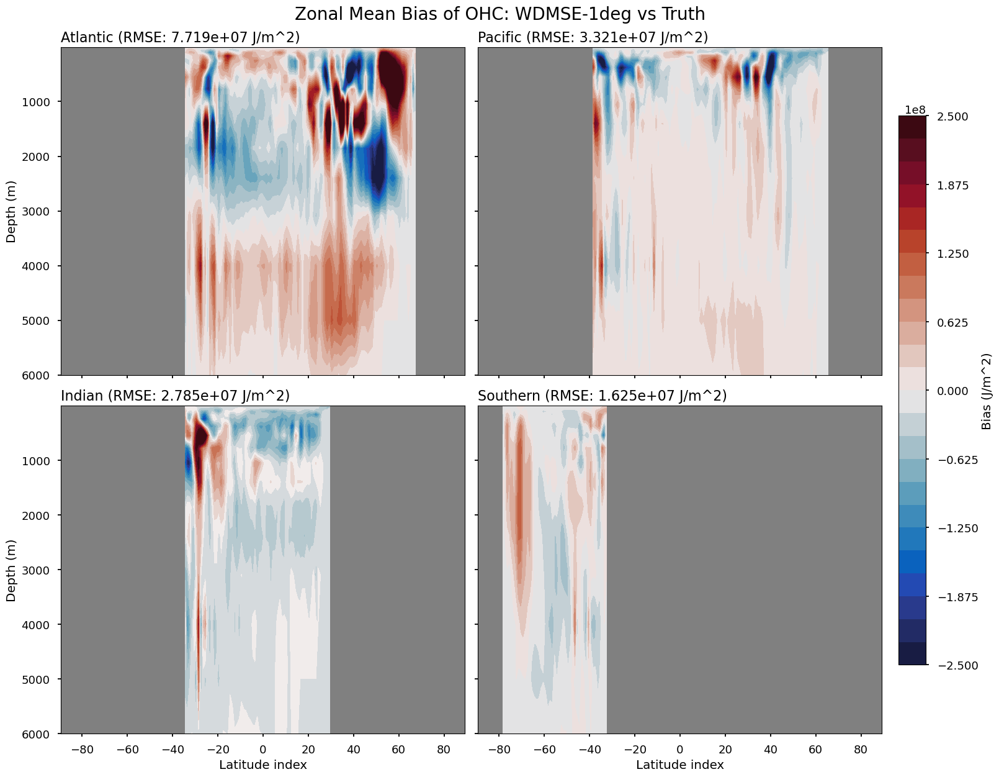

Calculating Truth Zonal Profiles for thetao...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Generating Zonal Bias Plot for WDMSE-1deg...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


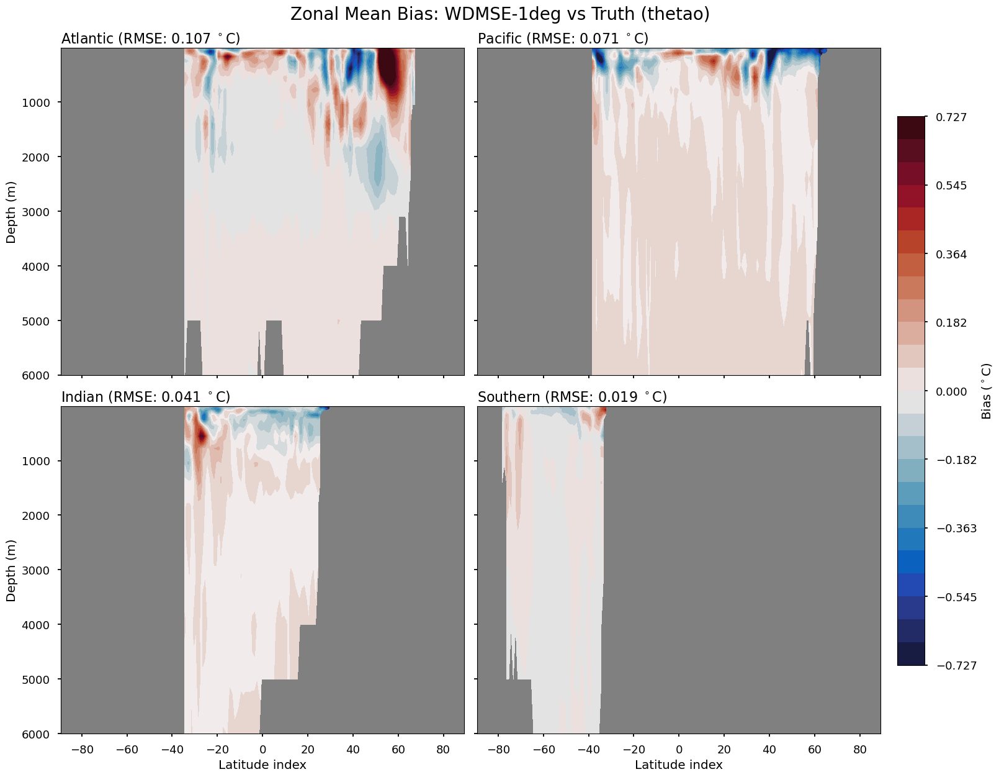

In [ ]:
# --- Execution ---

from functions import *

basin_masks = extract_basin_masks(dataset_truth)
# basin_masks needs to be derived from 2D basin file or sliced
plot_ohc_zonal_bias_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    masks=basin_masks,
    colorbar_fix=True
)

# 1. Zonal Bias (Thetao)
plot_zonal_bias_comparison(dataset_truth, emulators_to_analyze, 'thetao', '$^\\circ$C', basin_masks, OUTPUT_DIR,colorbar_fix=True)



Calculating Truth OHC Zonal Profiles...
Calculating OHC Zonal Bias for WDMSE-1/4deg...


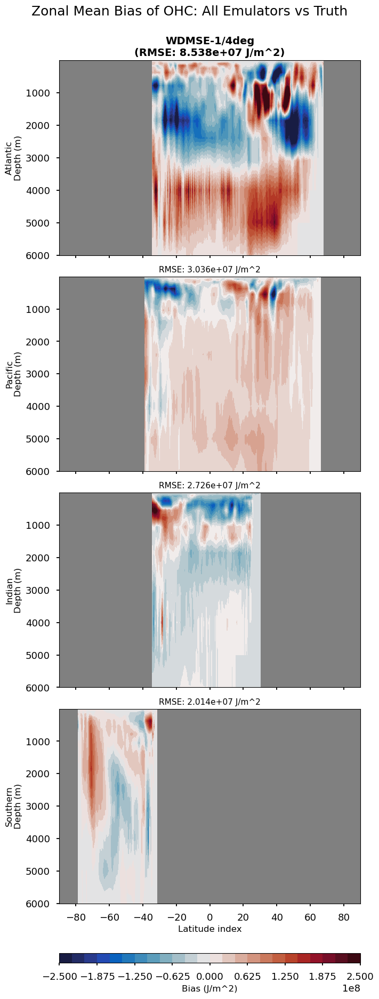

Calculating Truth Zonal Profiles for thetao...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating Zonal Bias for WDMSE-1/4deg...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


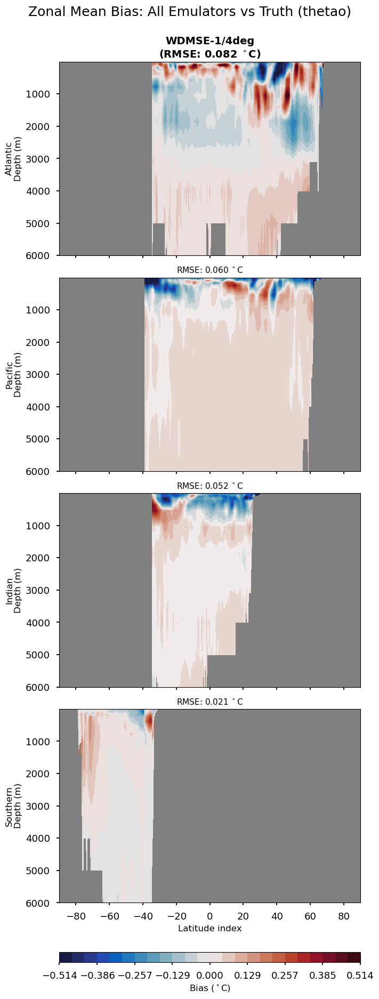

In [4]:
# --- Execution ---

from functions import *

basin_masks = extract_basin_masks(dataset_truth)
# basin_masks needs to be derived from 2D basin file or sliced
plot_ohc_zonal_bias_ocean_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    masks=basin_masks,
    colorbar_fix=True
)

# 1. Zonal Bias (Thetao)
plot_zonal_bias_ocean_comparison(dataset_truth, emulators_to_analyze, 'thetao', '$^\\circ$C', basin_masks, OUTPUT_DIR,colorbar_fix=True)




Processing time index: -100
Calculating Truth Zonal Profiles for thetao at time index -100...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating Zonal Bias for WDMSE-1/4deg at time index -100...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


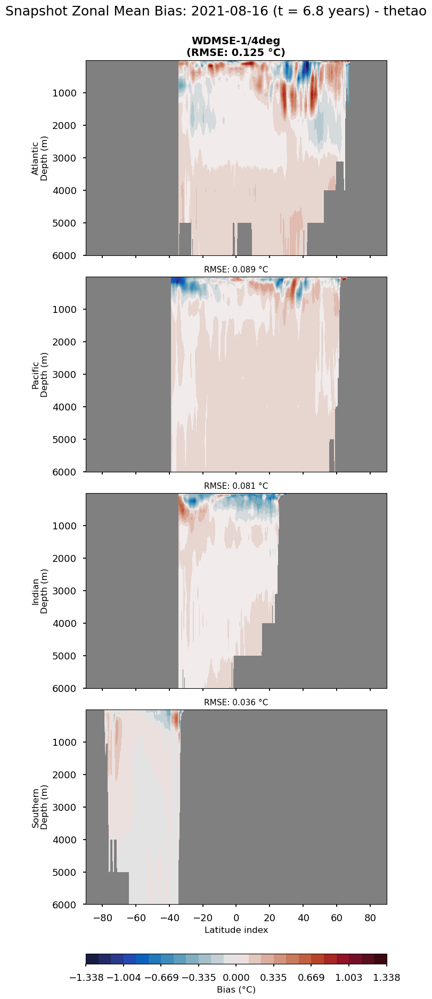


Processing time index: -50
Calculating Truth Zonal Profiles for thetao at time index -50...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating Zonal Bias for WDMSE-1/4deg at time index -50...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


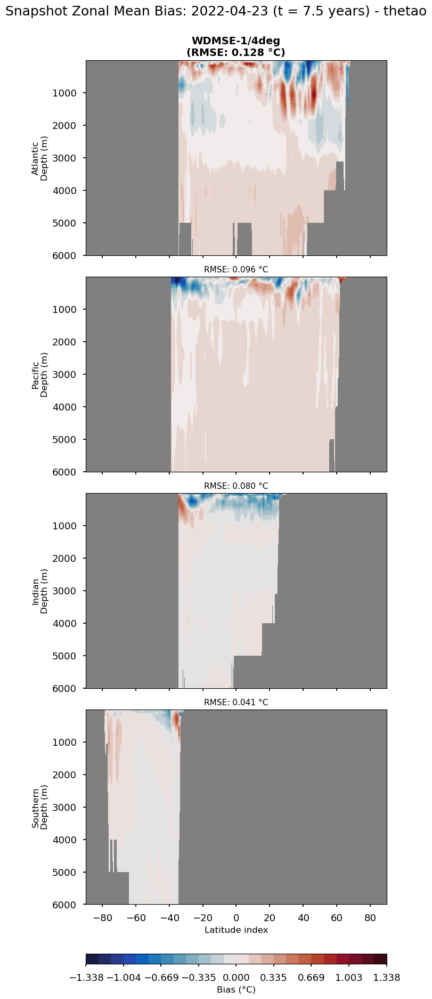


Processing time index: -1
Calculating Truth Zonal Profiles for thetao at time index -1...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating Zonal Bias for WDMSE-1/4deg at time index -1...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


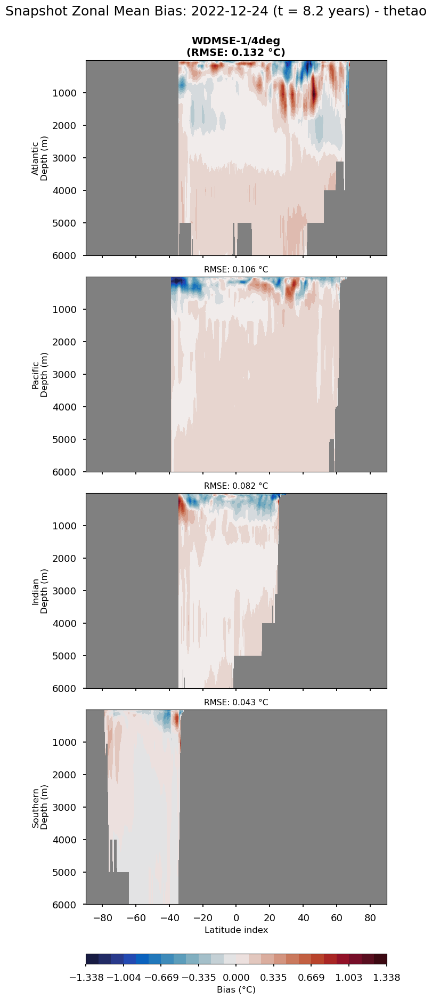


Processing time index: -100
Calculating Truth OHC Zonal Profiles at time index -100...
Calculating OHC Zonal Bias for WDMSE-1/4deg at time index -100...


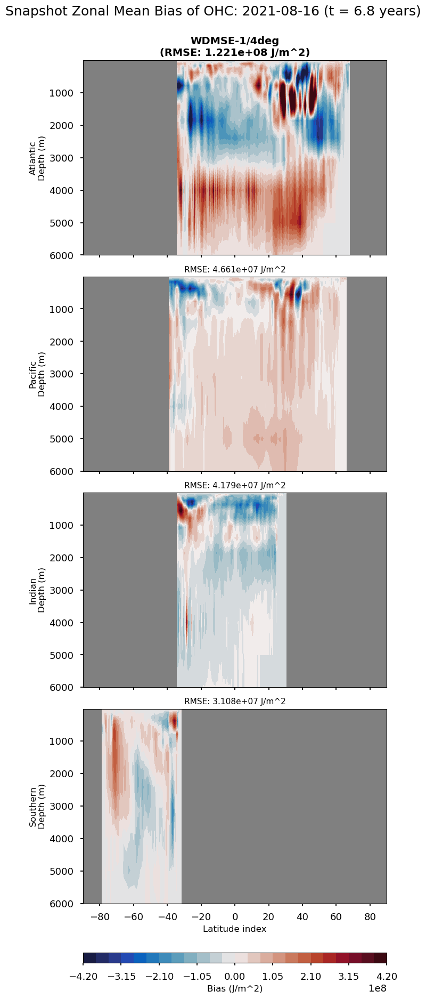


Processing time index: -50
Calculating Truth OHC Zonal Profiles at time index -50...
Calculating OHC Zonal Bias for WDMSE-1/4deg at time index -50...


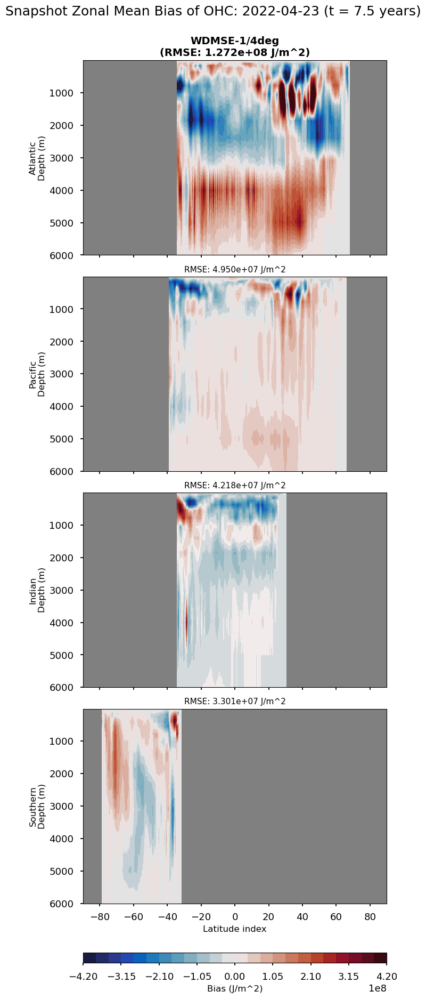


Processing time index: -1
Calculating Truth OHC Zonal Profiles at time index -1...
Calculating OHC Zonal Bias for WDMSE-1/4deg at time index -1...


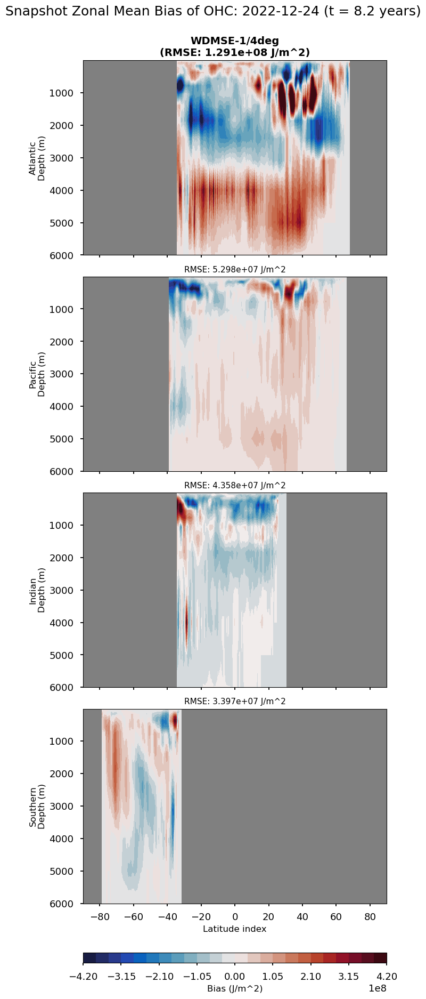

: 

In [ ]:
# --- Execution ---

from functions import *

basin_masks = extract_basin_masks(dataset_truth)
# basin_masks needs to be derived from 2D basin file or sliced

plot_snapshot_zonal_bias_ocean_comparison(
    ds_truth=dataset_truth,
    emulators_dict=emulators_to_analyze,
    variable_name='thetao',
    units='°C',
    masks=basin_masks,
    TIME_INDICES=[-100,-50,-1],
    colorbar_fix=True
)

plot_snapshot_ohc_zonal_bias_ocean_comparison(
    ds_truth=dataset_truth,
    emulators_dict=emulators_to_analyze,
    masks=basin_masks,
    TIME_INDICES=[-100,-50,-1],
    colorbar_fix=True
)

This is the same bias as above, but seperated into depth levels rather than basins.

In [ ]:
from functions import *

Plotting some OHC maps

Preparing Truth Metrics...
Calculating Truth OHC Maps...


Calculating OHC Maps for WDMSE-1deg...


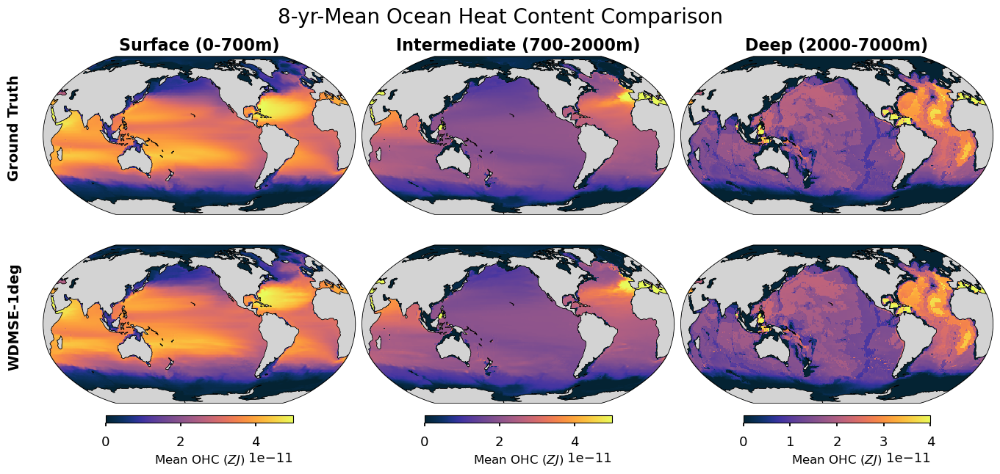

In [ ]:
# --- Execution ---
plot_ohc_mean_comparison(dataset_truth, emulators_to_analyze,TRUTH_LABEL=TRUTH_LABEL,colorbar_fix=True)

Preparing Truth Metrics...
Calculating Truth Temperature Maps...
Calculating Temperature Maps for WDMSE-1deg...
2 4 2


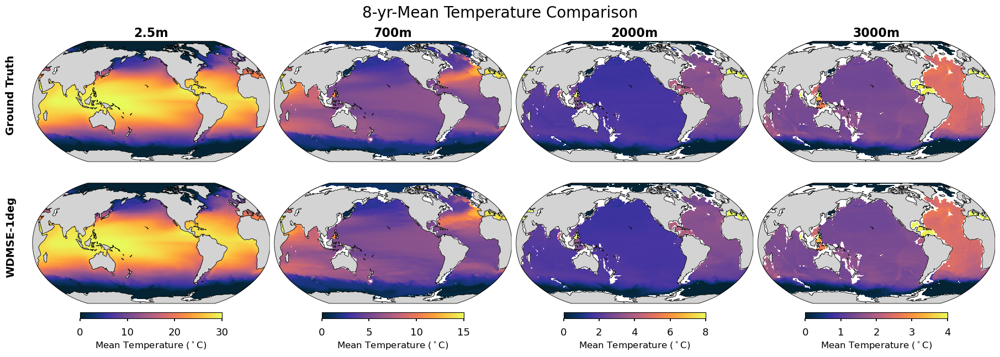

In [ ]:


# --- Execution ---
plot_temperature_mean_comparison(dataset_truth, emulators_to_analyze,TRUTH_LABEL = TRUTH_LABEL,colorbar_fix=True)

Preparing Truth Metrics...
Calculating Truth Zonal Profiles...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating Temperature Maps for WDMSE-1deg...

Generating Zonal Bias Plot for WDMSE-1deg...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


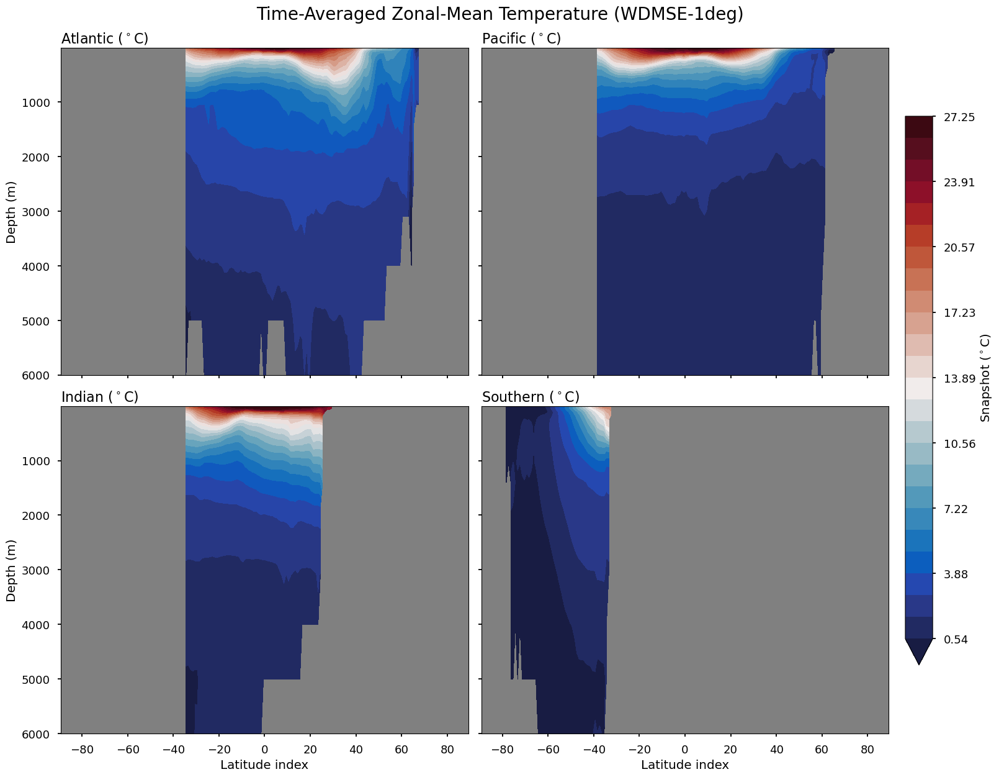

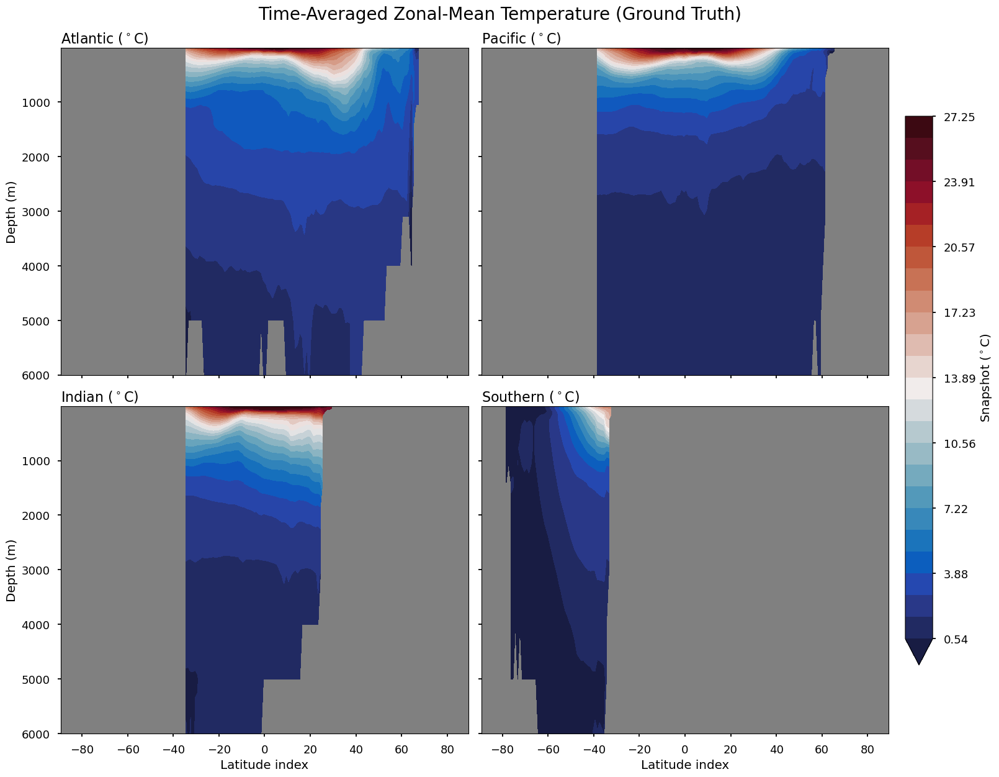

In [ ]:
from functions import *
# --- Execution ---
basin_masks = extract_basin_masks(dataset_truth)

plot_zonal_mean_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks=basin_masks,
    colorbar_fix=True
)

Preparing Truth Metrics...
Calculating Truth Zonal Profiles...
Calculating OHC Maps for WDMSE-1deg...

Generating Zonal Mean Plot for WDMSE-1deg...


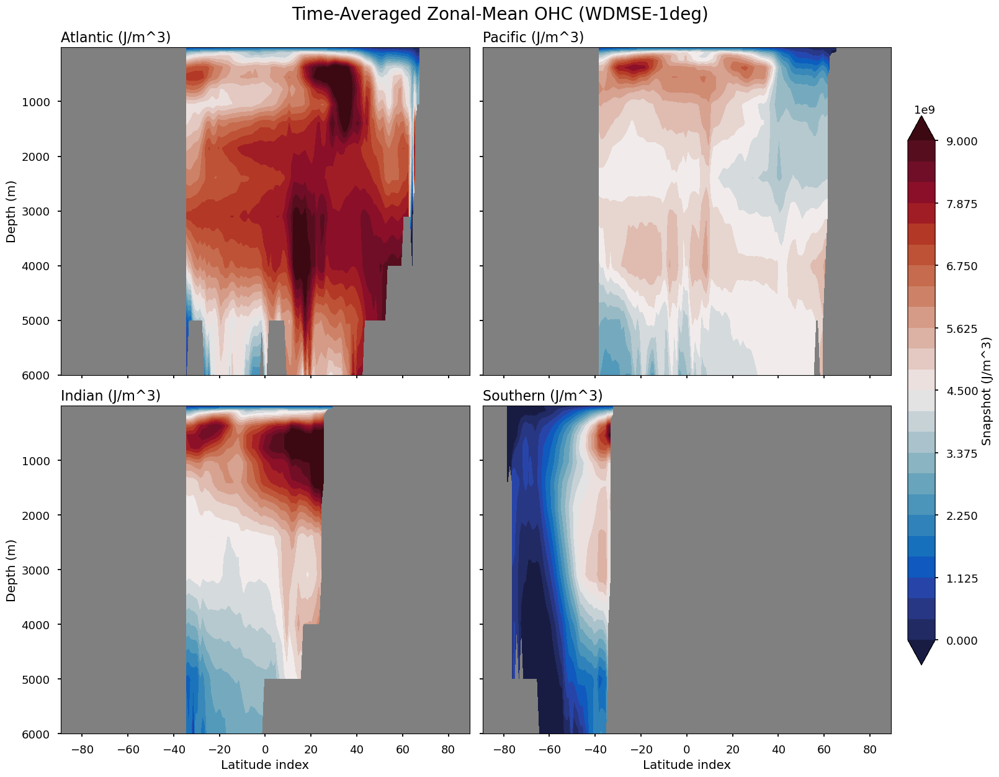

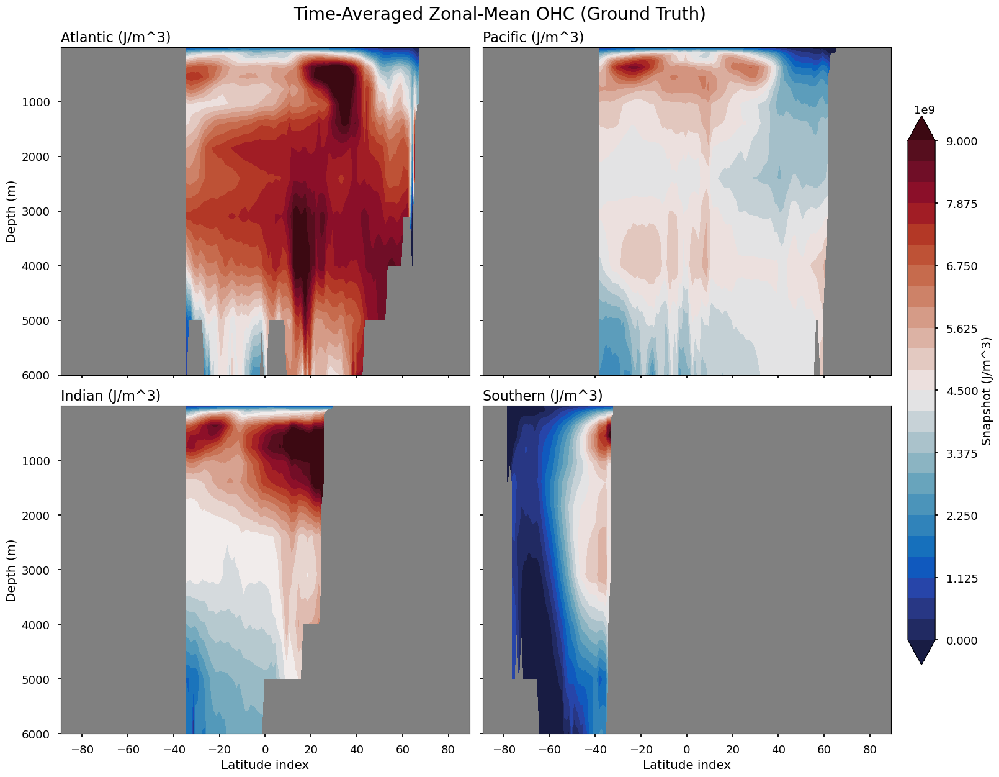

In [ ]:
from functions import *

basin_masks = extract_basin_masks(dataset_truth)

plot_ohc_zonal_mean_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks=basin_masks,
    colorbar_fix=True 
)


Preparing Truth Metrics...
Calculating Truth Zonal Profiles...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating Temperature Maps for WDMSE-1deg...

Generating Zonal Bias Plot for WDMSE-1deg...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


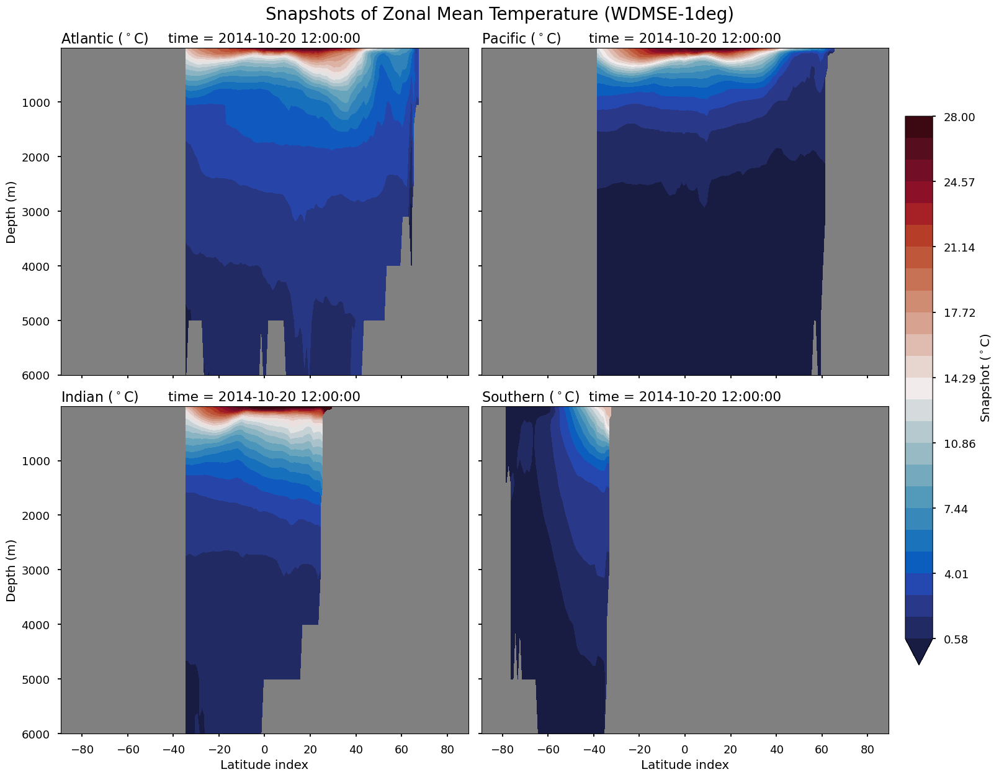

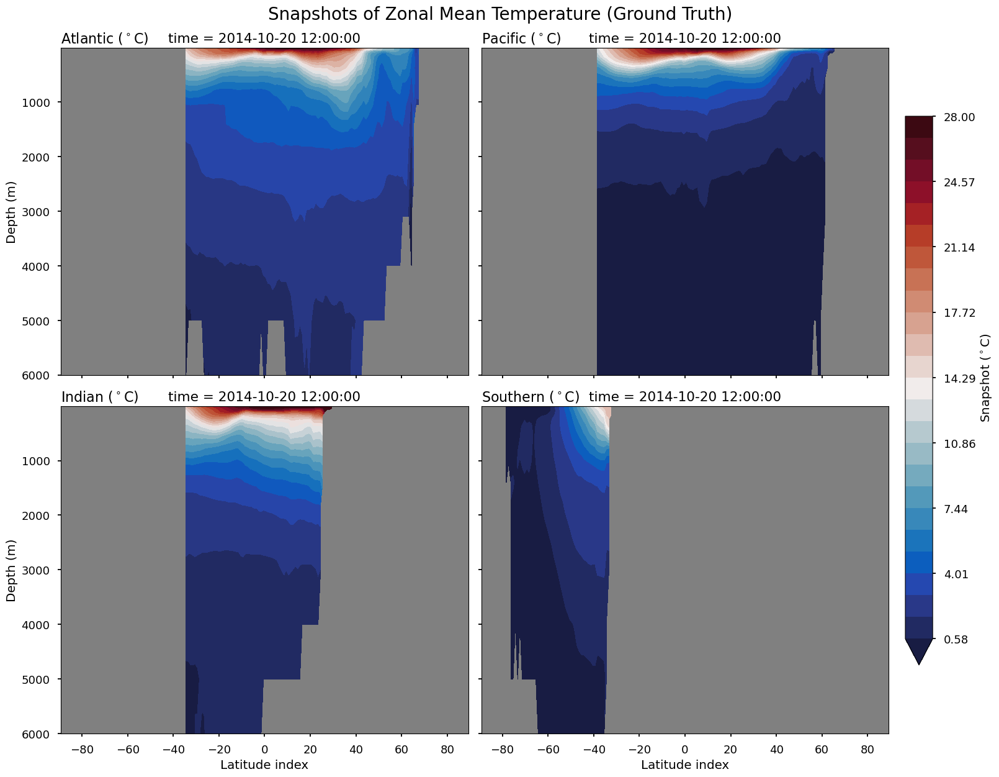

In [ ]:
# --- Execution ---
basin_masks = extract_basin_masks(dataset_truth)

plot_zonal_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks=basin_masks,
    colorbar_fix=True
)


Preparing Truth Metrics...

Processing time index: -100
Calculating Truth Zonal Profiles at time index -100...
Calculating OHC profiles for WDMSE-1deg at time index -100...


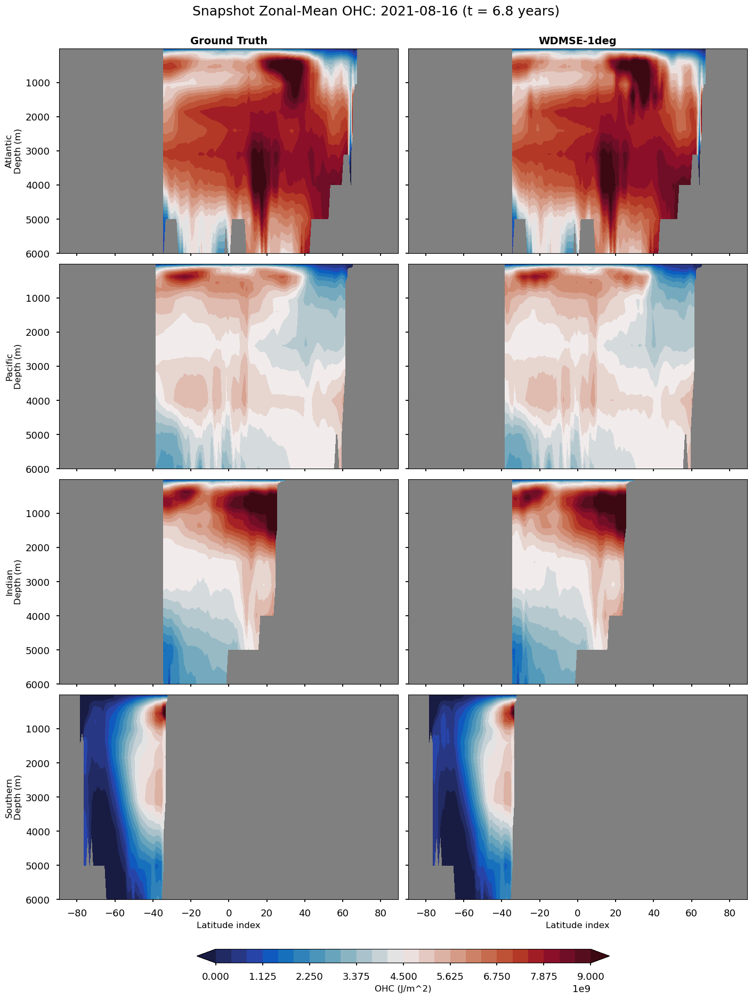


Processing time index: -50
Calculating Truth Zonal Profiles at time index -50...
Calculating OHC profiles for WDMSE-1deg at time index -50...


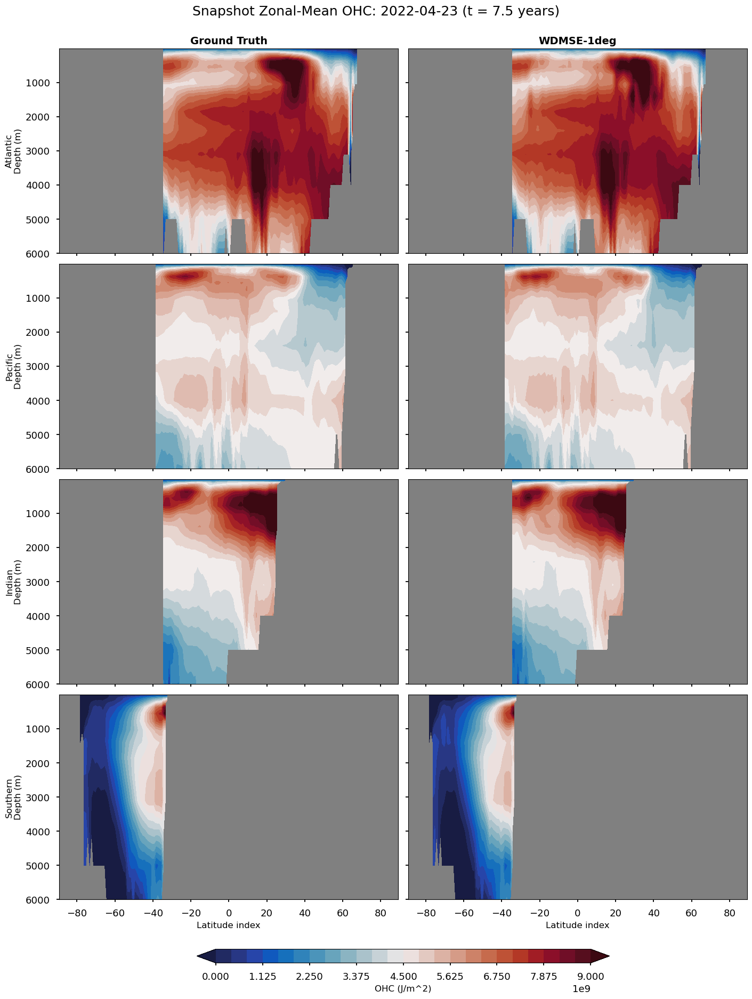


Processing time index: -1
Calculating Truth Zonal Profiles at time index -1...
Calculating OHC profiles for WDMSE-1deg at time index -1...


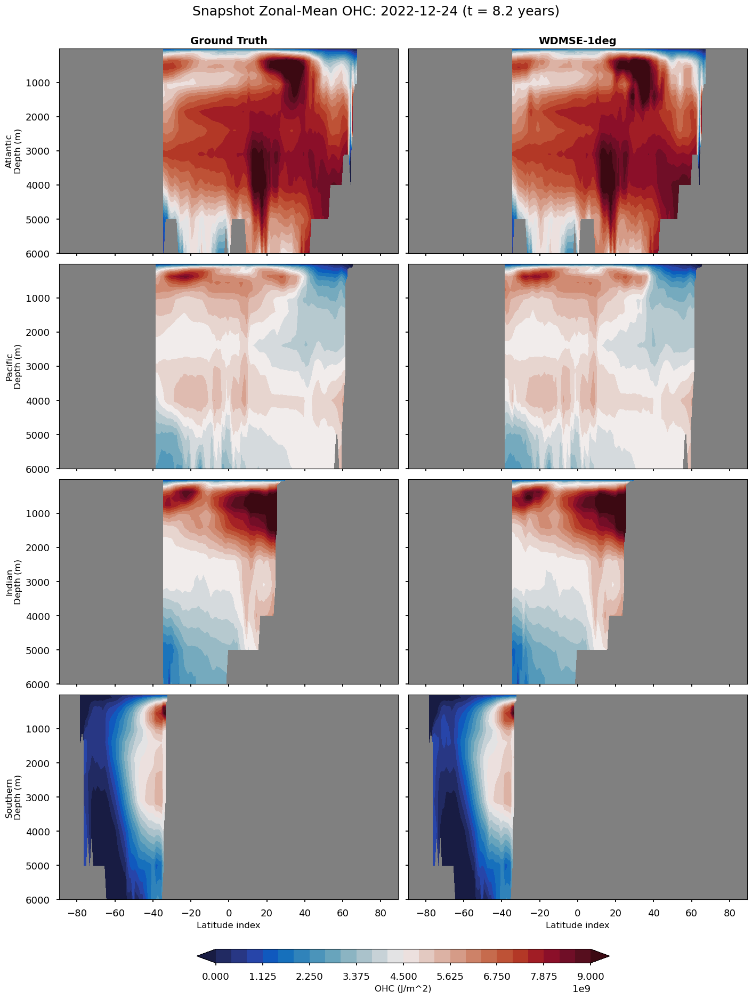

In [ ]:
# --- Execution ---
basin_masks = extract_basin_masks(dataset_truth)
from functions import *
plot_ohc_zonal_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks=basin_masks,
    TIME_INDICES = [-100, -50, -1],
    colorbar_fix=True
)

Preparing Truth Metrics...

Processing time index: -100
Calculating Truth Zonal Profiles at time index -100...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating thetao profiles for WDMSE-1deg at time index -100...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


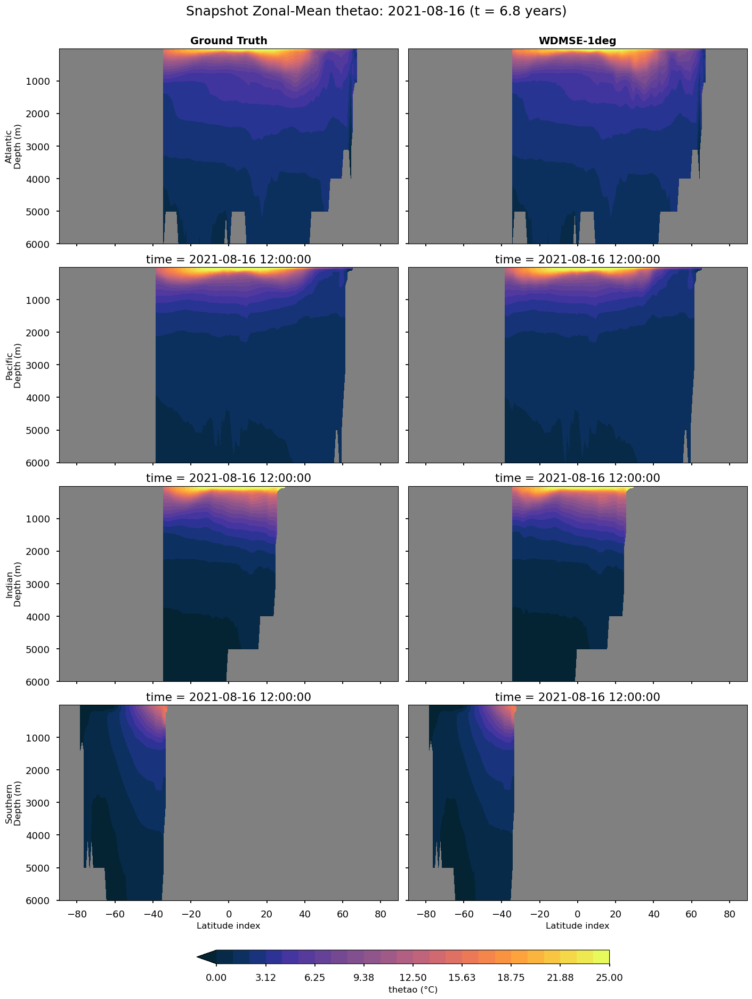


Processing time index: -50
Calculating Truth Zonal Profiles at time index -50...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating thetao profiles for WDMSE-1deg at time index -50...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


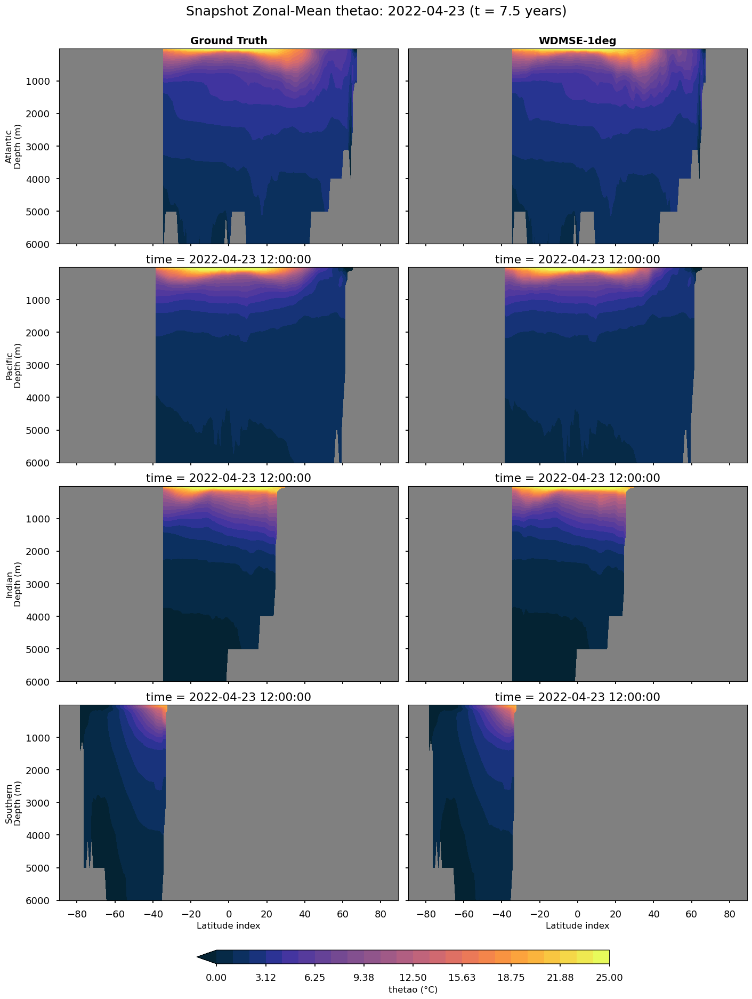


Processing time index: -1
Calculating Truth Zonal Profiles at time index -1...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Calculating thetao profiles for WDMSE-1deg at time index -1...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


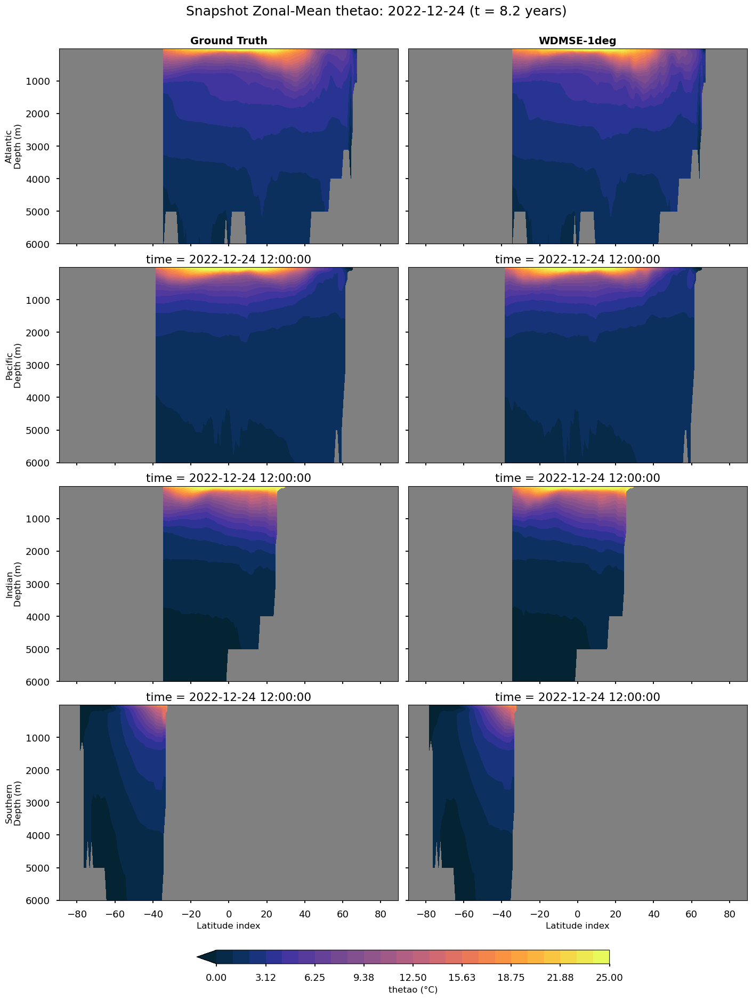

In [ ]:
basin_masks = extract_basin_masks(dataset_truth)
plot_zonal_mean_snapshot_comparison(
    ds_truth=dataset_truth,
    emulators_dict=emulators_to_analyze,
    variable_name='thetao',
    units='°C',
    masks=basin_masks,
    TIME_INDICES = [-100, -50, -1],  # Your desired time indices
    colorbar_fix=True
)

Preparing Truth Metrics...
Calculating Truth OHC Maps...
Calculating OHC Maps for WDMSE-1/4deg...
  > Bias Range (98th percentile): +/- 0.000 ZJ
local_max:  2.3696045e-12
  > Surface (0-700m) Scale locked to: +/- 2.370e-12 ZJ
local_max:  2.3559418e-12
  > Intermediate (700-2000m) Scale locked to: +/- 2.356e-12 ZJ
local_max:  1.1848543e-12
  > Deep (2000-7000m) Scale locked to: +/- 1.185e-12 ZJ


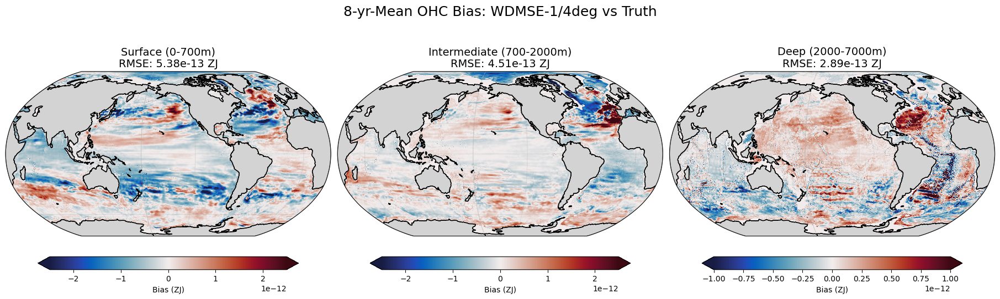

In [4]:


# --- Execution ---
plot_ohc_bias_comparison(dataset_truth, emulators_to_analyze,colorbar_fix=True)


Preparing Truth Metrics...
Calculating Truth Temperature Maps...
Calculating Temperature Maps for WDMSE-1deg...
  > Bias Range (98th percentile): +/- 1.113 $^\circ$C
  > 2.5m Scale locked to: +/- 1.263e+00 $^\circ$C
  > 700m Scale locked to: +/- 7.165e-01 $^\circ$C
  > 2000m Scale locked to: +/- 1.673e-01 $^\circ$C
  > 3000m Scale locked to: +/- 1.015e-01 $^\circ$C


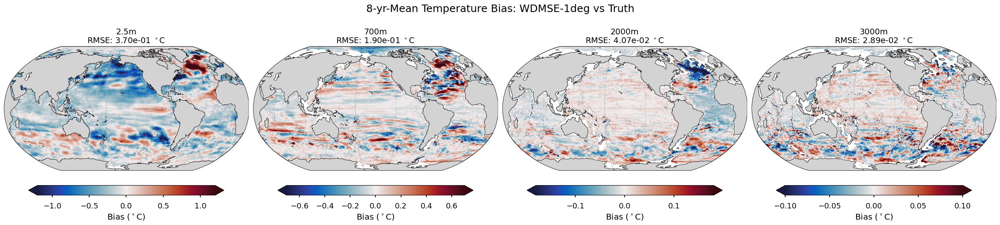

In [ ]:
from functions import *
# --- Execution ---
plot_temperature_bias_comparison(dataset_truth, emulators_to_analyze,colorbar_fix=True)

Preparing Truth Metrics...

Creating plot for time point: 2021-08-16 12:00:00
  Calculating OHC Snapshot Maps for WDMSE-1/4deg...
    > Surface (0-700m) Scale locked to: +/- 4.723e-12 ZJ
    > Intermediate (700-2000m) Scale locked to: +/- 4.093e-12 ZJ
    > Deep (2000-7000m) Scale locked to: +/- 2.022e-12 ZJ


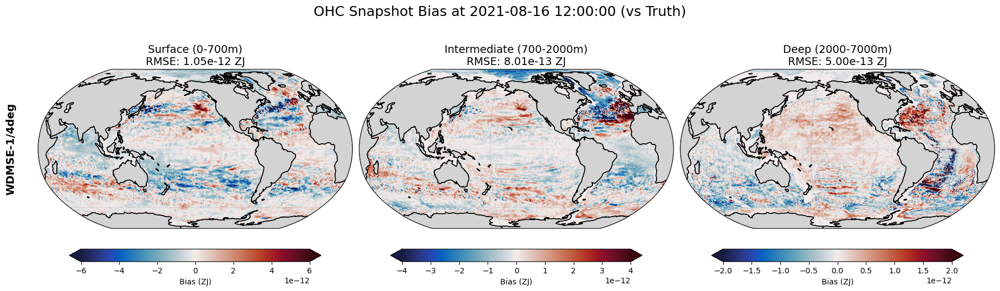


Creating plot for time point: 2022-04-23 12:00:00
  Calculating OHC Snapshot Maps for WDMSE-1/4deg...
    > Surface (0-700m) Scale locked to: +/- 4.657e-12 ZJ
    > Intermediate (700-2000m) Scale locked to: +/- 4.370e-12 ZJ
    > Deep (2000-7000m) Scale locked to: +/- 2.106e-12 ZJ


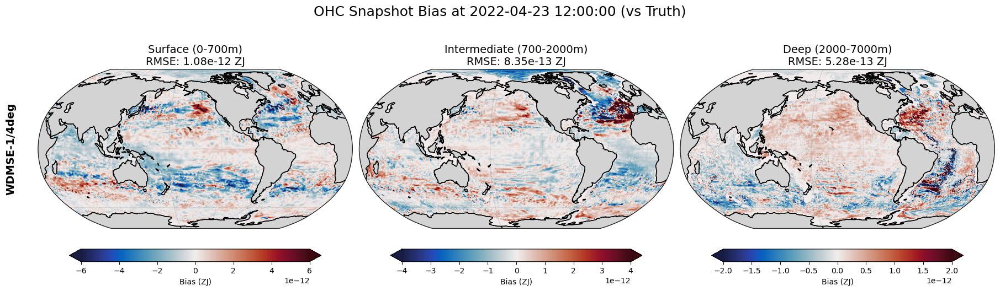


Creating plot for time point: 2022-12-24 12:00:00
  Calculating OHC Snapshot Maps for WDMSE-1/4deg...
    > Surface (0-700m) Scale locked to: +/- 4.901e-12 ZJ
    > Intermediate (700-2000m) Scale locked to: +/- 4.422e-12 ZJ
    > Deep (2000-7000m) Scale locked to: +/- 2.177e-12 ZJ


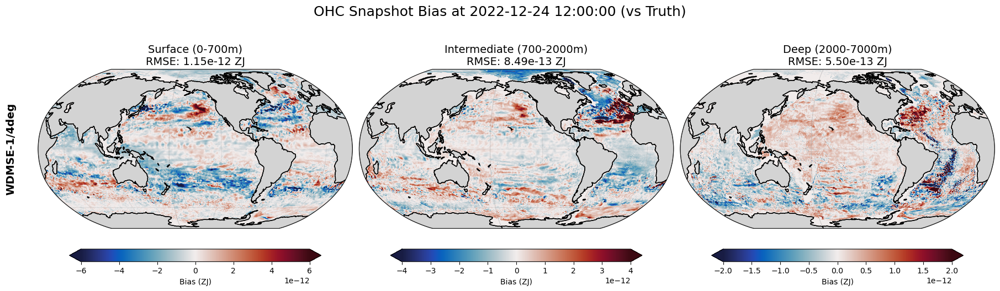

In [4]:
TIME_INDICES = [-100, -50, -1]
from functions import *
plot_ohc_snapshot_bias_comparison(dataset_truth, emulators_to_analyze, TIME_INDICES, colorbar_fix=True)

Preparing Truth Metrics...

Creating plot for time point: 2021-08-16 12:00:00
  Calculating Temperature Snapshot Maps for WDMSE-1/4deg...


    > 2.5m Scale locked to: +/- 2.187e+00 $^\circ$C
    > 700m Scale locked to: +/- 1.319e+00 $^\circ$C
    > 2000m Scale locked to: +/- 2.827e-01 $^\circ$C
    > 3000m Scale locked to: +/- 1.965e-01 $^\circ$C


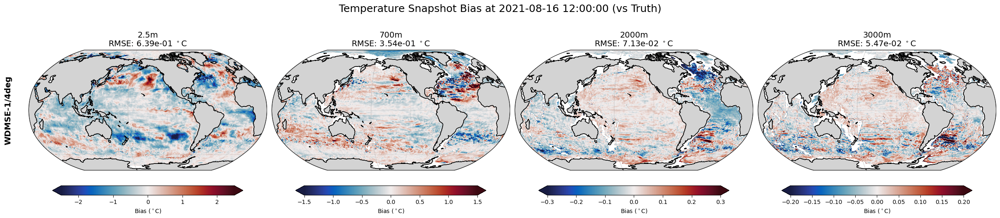


Creating plot for time point: 2022-04-23 12:00:00
  Calculating Temperature Snapshot Maps for WDMSE-1/4deg...
    > 2.5m Scale locked to: +/- 2.099e+00 $^\circ$C
    > 700m Scale locked to: +/- 1.333e+00 $^\circ$C
    > 2000m Scale locked to: +/- 2.830e-01 $^\circ$C
    > 3000m Scale locked to: +/- 1.975e-01 $^\circ$C


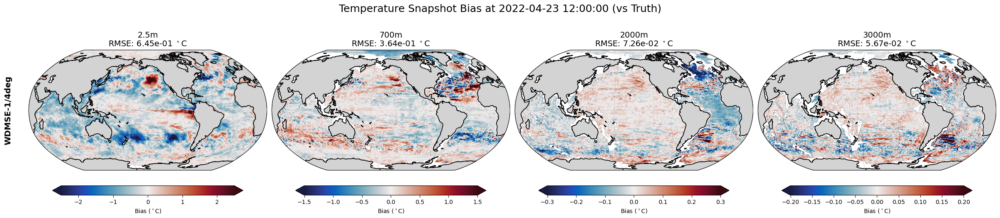


Creating plot for time point: 2022-12-24 12:00:00
  Calculating Temperature Snapshot Maps for WDMSE-1/4deg...
    > 2.5m Scale locked to: +/- 2.638e+00 $^\circ$C
    > 700m Scale locked to: +/- 1.351e+00 $^\circ$C
    > 2000m Scale locked to: +/- 2.972e-01 $^\circ$C
    > 3000m Scale locked to: +/- 2.025e-01 $^\circ$C


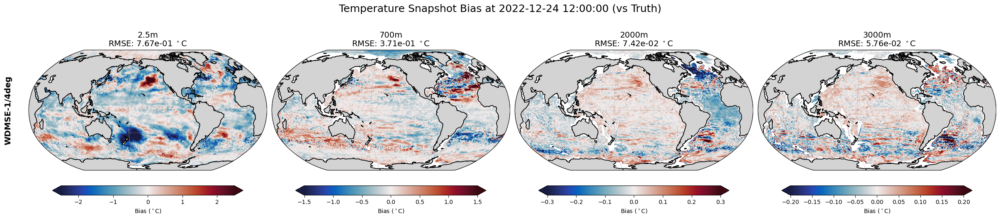

In [5]:
from functions import *
plot_temperature_snapshot_bias_comparison(dataset_truth, emulators_to_analyze, TIME_INDICES, colorbar_fix=True)


Preparing Snapshot Maps for Temperature (2.5m)...


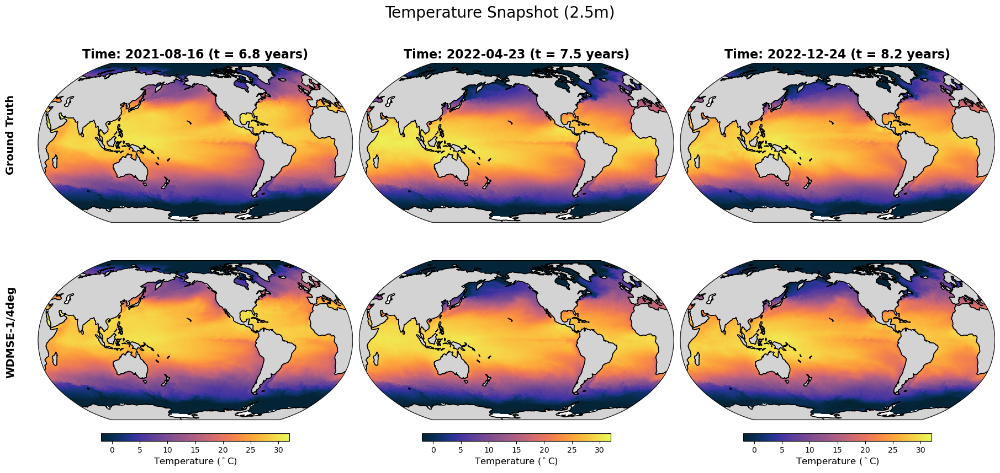

Preparing Snapshot Maps for Temperature (700m)...


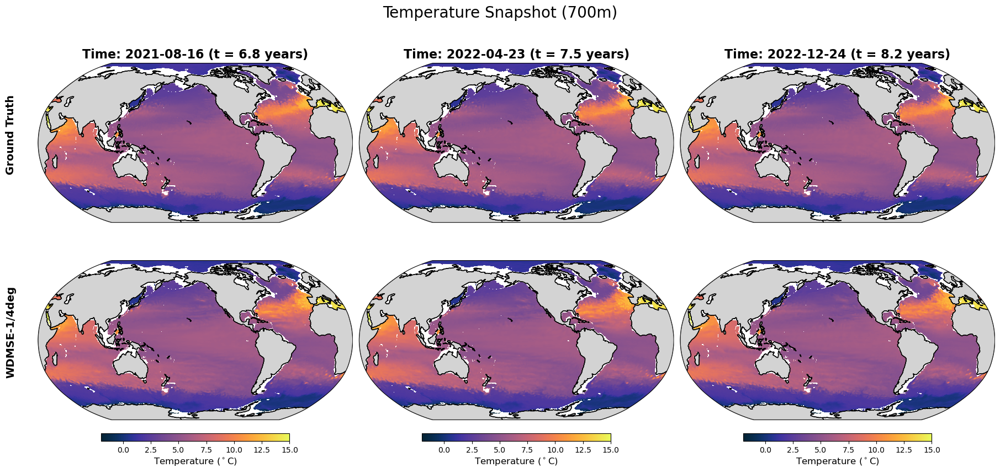

Preparing Snapshot Maps for Temperature (2000m)...


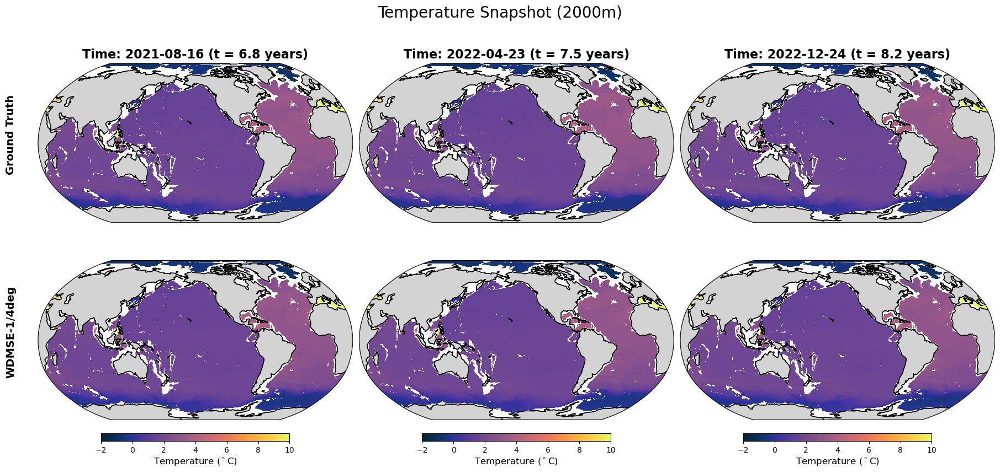

Preparing Snapshot Maps for Temperature (3000m)...


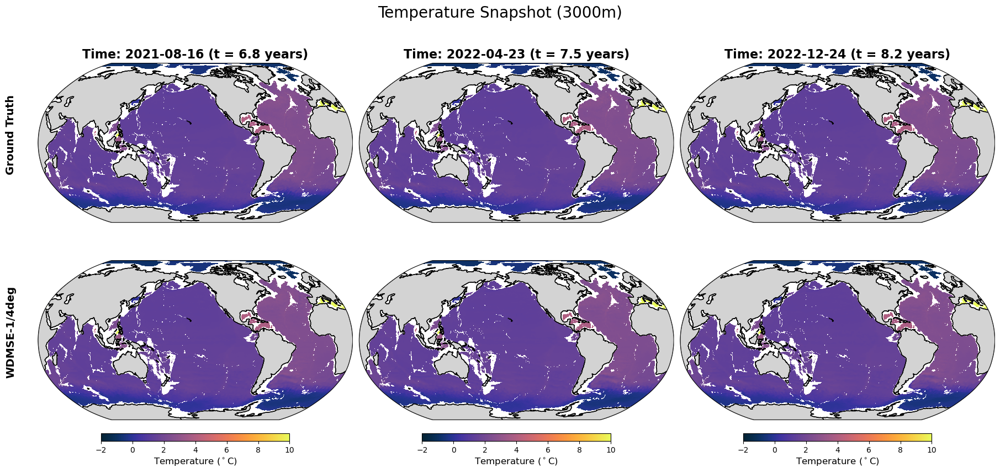

In [6]:
from functions import *
# --- Configuration ---
VARIABLE_TO_PLOT = 'thetao'  # Options: 'thetao', 'so', 'zos', 'uo', 'vo'
TIME_INDICES = [-100, -50, -1]   # Index of time steps to plot (e.g. Initial, Short, Long)

# --- Execution ---
plot_snapshot_comparison_SpecificLayer(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_LAYERS[0],
    fix_colorbar=True
)
plot_snapshot_comparison_SpecificLayer(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_LAYERS[1],
    fix_colorbar=True
)
plot_snapshot_comparison_SpecificLayer(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_LAYERS[2],
    fix_colorbar=True
)

plot_snapshot_comparison_SpecificLayer(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_LAYERS[3],
    fix_colorbar=True
)

In [7]:
DEPTH_LAYERS[3]

{'title': '3000m', 'index': 15}

In [8]:
DEPTH_LAYERS

[{'title': '2.5m', 'index': 0},
 {'title': '700m', 'index': 10},
 {'title': '2000m', 'index': 14},
 {'title': '3000m', 'index': 15}]

Preparing Snapshot Maps for OHC (Surface (0-700m))...


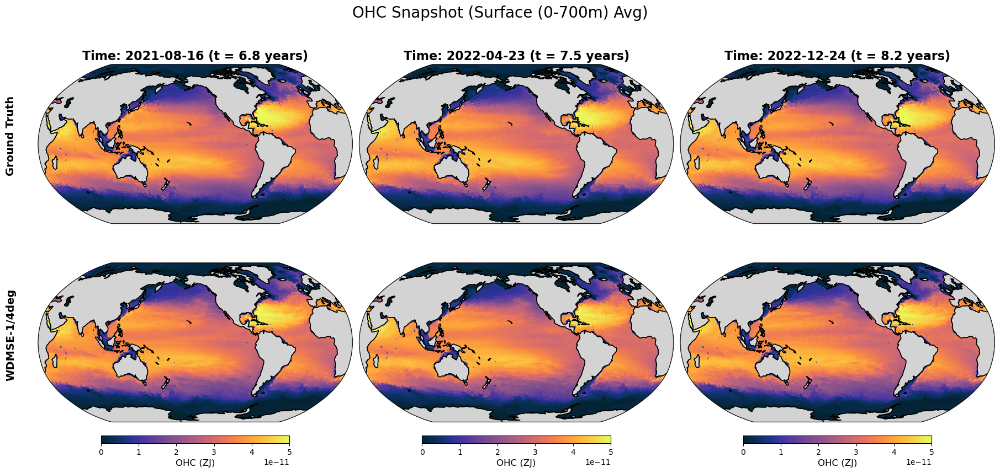

Preparing Snapshot Maps for OHC (Intermediate (700-2000m))...


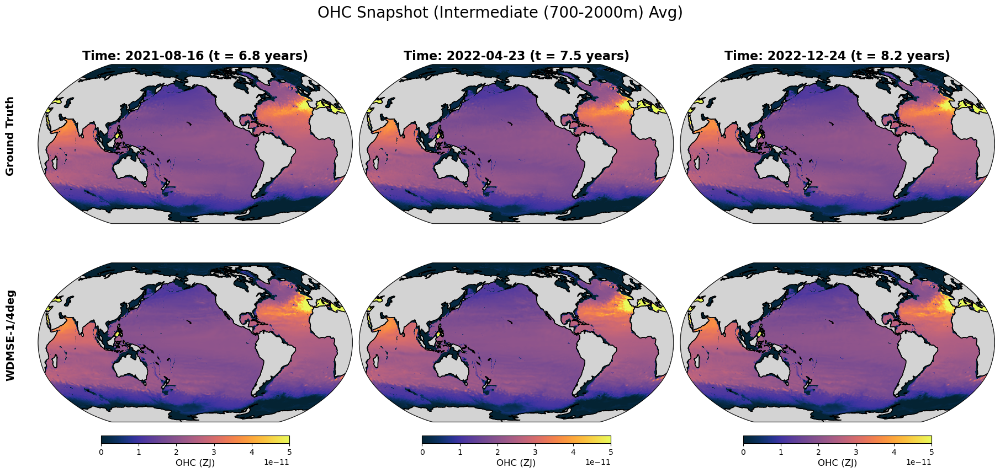

Preparing Snapshot Maps for OHC (Deep (2000-7000m))...


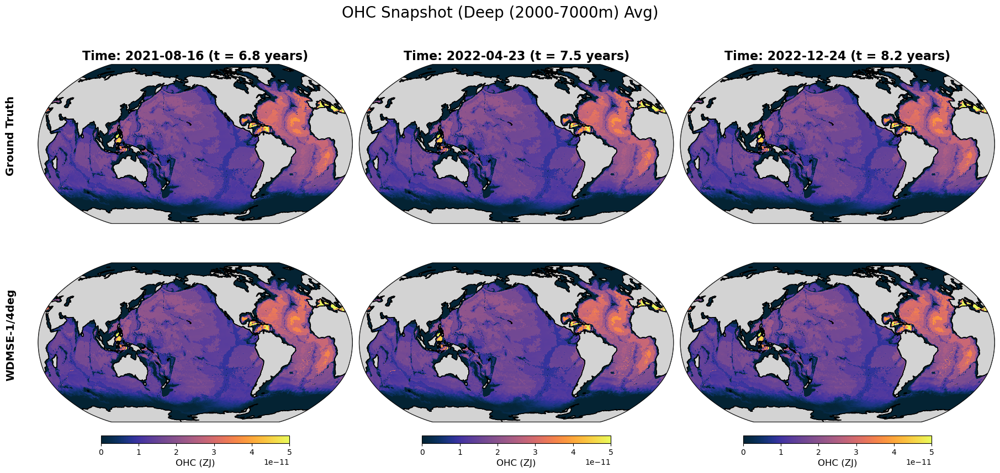

In [9]:
from functions import *

VARIABLE_TO_PLOT = 'thetao'

TIME_INDICES = [-100, -50, -1]   # Index of time steps to plot (e.g. Initial, Short, Long)

# --- Execution ---
plot_ohc_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_SLICES[0],
    colorbar_fix=True
)
plot_ohc_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_SLICES[1],
    colorbar_fix=True
)
plot_ohc_snapshot_comparison(
    dataset_truth, 
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_config=DEPTH_SLICES[2],
    colorbar_fix=True
)
